In [18]:
# ===== SETUP CELL v2: run first. Imports, paths, settings, helper functions =====
import os, time, calendar, json, hashlib, subprocess
import numpy as np, pandas as pd
from pathlib import Path
from dotenv import load_dotenv

# ---- paths (notebook sits in precipitation/notebooks/) ----
ROOT      = Path("..")                    # precipitation/
INTERIM   = ROOT / "data" / "interim"     # imd_rainfall_YYYY.csv
RAW       = ROOT / "data" / "raw"         # nino34, dmi
PROCESSED = ROOT / "data" / "processed"   # new v2 files go here, new names only
POINT_REGION_FILE = PROCESSED / "point_region_v2.csv"

# ---- secrets (never print these) ----
load_dotenv("../../.env")
DAGSHUB_TOKEN = os.getenv("DAGSHUB_USER_TOKEN")

# ---- decisions ----
START_YEAR, END_YEAR = 1901, 2025
YEARS       = list(range(START_YEAR, END_YEAR + 1))
TRAIN_END   = 2002                         # train: START_YEAR to 2002
VAL_YEARS   = (2003, 2013)                 # val
TEST_YEARS  = (2014, 2025)                 # test: untouched until the final step
WINDOW      = 3                            # target = months t+1 to t+3
SD_FLOOR    = None                         # choose from the data in Phase 2, then record in params
BLOCK_BOOT  = "year"                       # bootstrap resamples whole years
REGIONS     = ["northwest", "central", "south_peninsula", "east_northeast"]
REGION_RULE = "IMD four regions by state; points outside every polygon go to the nearest state"

# known data gap: 79 points have no data on this date (all other days complete)
GAP_DATE   = "2023-10-12"
GAP_RULE   = "set that point's Oct 2023 total to missing; drop only rows that use it"

# ---- file names ----
RAIN_FILE_FMT = "imd_rainfall_{year}.csv"
NINO_FILE, DMI_FILE = "nino34.long.anom.csv", "dmi.had.long.csv"

# ---- helper functions (they take data as arguments, no hidden globals) ----
def rain_path(year):
    return INTERIM / RAIN_FILE_FMT.format(year=year)

def load_year(year):
    """One year of daily rainfall, float32 to save memory.
    Columns: date (str), latitude, longitude, rainfall_mm."""
    return pd.read_csv(rain_path(year),
                       dtype={"latitude": "float32", "longitude": "float32",
                              "rainfall_mm": "float32"})

def point_key(lat, lon):
    """Integer id for a 0.25 degree point. Safe for merging (no float issues)."""
    lat = np.asarray(lat, dtype="float64"); lon = np.asarray(lon, dtype="float64")
    return (np.round(lat * 100).astype("int64") * 10000
            + np.round(lon * 100).astype("int64"))

def load_index(file_name, out_name):
    """Nino 3.4 or DMI. Renames the long columns by position, turns -9999 / -99.99 into NaN."""
    d = pd.read_csv(RAW / file_name).iloc[:, :2].copy()
    d.columns = ["date", out_name]
    d["date"] = pd.to_datetime(d["date"])
    d.loc[d[out_name] <= -99, out_name] = np.nan
    return d

def load_indices():
    """Nino 3.4 and DMI merged by exact month, one row per month."""
    n = load_index(NINO_FILE, "nino34")
    m = load_index(DMI_FILE, "dmi")
    return n.merge(m, on="date", how="outer").sort_values("date").reset_index(drop=True)

def get_points():
    """The 0.25 degree points with key and region. Points from the 2025 file,
    region and state from point_region_v2.csv (built from the state boundary file)."""
    p = pd.read_csv(rain_path(2025), usecols=["latitude", "longitude"]).drop_duplicates()
    p["latitude"] = p.latitude.round(2); p["longitude"] = p.longitude.round(2)
    p = p.sort_values(["latitude", "longitude"]).reset_index(drop=True)
    p["key"] = point_key(p.latitude, p.longitude)
    r = pd.read_csv(POINT_REGION_FILE, usecols=["key", "state", "region"])
    assert r.key.is_unique, "duplicate keys in point_region_v2.csv"
    p = p.merge(r, on="key", how="left", validate="one_to_one")
    assert p.region.notna().all(), "points without a region"
    assert set(p.region.unique()) <= set(REGIONS), "unknown region name"
    return p

def split_of(year):
    """Which split a year belongs to (by year only; buffer rows are handled in Phase 2)."""
    if year <= TRAIN_END: return "train"
    if VAL_YEARS[0] <= year <= VAL_YEARS[1]: return "val"
    if TEST_YEARS[0] <= year <= TEST_YEARS[1]: return "test"
    return None

def git_commit():
    """Short git hash, for the MLflow tag."""
    try:
        return subprocess.check_output(["git", "rev-parse", "--short", "HEAD"], text=True).strip()
    except Exception:
        return None

def file_md5(path):
    """md5 of a file, for the dataset tag."""
    h = hashlib.md5()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

# ---- load the small things once ----
PTS = get_points()
INDICES = load_indices()

# ---- quick self-check (prints only) ----
print("start/end year:", START_YEAR, END_YEAR, "| years:", len(YEARS))
print("splits: train <=", TRAIN_END, "| val", VAL_YEARS, "| test", TEST_YEARS)
print("rain files present:", sum(rain_path(y).exists() for y in YEARS), "of", len(YEARS))
print("points:", len(PTS))
print(PTS.region.value_counts().to_dict())
print("indices rows:", len(INDICES),
      "| last valid nino34:", INDICES.dropna(subset=["nino34"]).date.max().date(),
      "| last valid dmi:", INDICES.dropna(subset=["dmi"]).date.max().date())
print("dagshub token loaded:", bool(DAGSHUB_TOKEN))
print("known gap:", GAP_DATE, "|", GAP_RULE)

start/end year: 1901 2025 | years: 125
splits: train <= 2002 | val (2003, 2013) | test (2014, 2025)
rain files present: 125 of 125
points: 4964
{'northwest': 1633, 'central': 1596, 'south_peninsula': 880, 'east_northeast': 855}
indices rows: 1884 | last valid nino34: 2026-09-01 | last valid dmi: 2026-07-01
dagshub token loaded: True
known gap: 2023-10-12 | set that point's Oct 2023 total to missing; drop only rows that use it


In [3]:
from pathlib import Path
import pandas as pd

ROOT = Path("..")  # precipitation/ (notebook is in precipitation/notebooks/)
interim = ROOT / "data" / "interim"
raw = ROOT / "data" / "raw"
proc = ROOT / "data" / "processed"

def f(y):
    return interim / f"imd_rainfall_{y}.csv"

# 1. daily files: all years present, same columns in every file?
years = list(range(1901, 2026))
missing = [y for y in years if not f(y).exists()]
print("missing year files:", missing)

headers = {y: tuple(pd.read_csv(f(y), nrows=0).columns)
           for y in years if f(y).exists()}
print("different column layouts across files:", len(set(headers.values())))
for h in set(headers.values()):
    ys = [y for y, v in headers.items() if v == h]
    print(list(h), "-> years", ys[0], "to", ys[-1], f"({len(ys)} files)")

# sample files: first, middle, last
for y in [1901, 1951, 2025]:
    df = pd.read_csv(f(y))
    print(f"\n===== {y} =====")
    print("shape:", df.shape)
    print(df.head(3))
    print(df.dtypes)
    print(df.describe().T)

# 3. location lookup
loc = pd.read_csv(proc / "location_lookup.csv")
print("\n===== location_lookup =====")
print("shape:", loc.shape)
print(loc.head(5))
print("nulls:\n", loc.isna().sum())
for c in loc.columns:
    if loc[c].dtype == object and loc[c].nunique() < 80:
        print(f"\ncounts for {c}:")
        print(loc[c].value_counts(dropna=False))

# 4. Nino 3.4 and DMI
for name in ["nino34.long.anom.csv", "dmi.had.long.csv"]:
    d = pd.read_csv(raw / name)
    print(f"\n===== {name} =====")
    print("shape:", d.shape)
    print(d.head(3))
    print(d.tail(3))
    print(d.dtypes)
    print(d.describe().T)

missing year files: []
different column layouts across files: 1
['date', 'latitude', 'longitude', 'rainfall_mm'] -> years 1901 to 2025 (125 files)

===== 1901 =====
shape: (1811860, 4)
         date  latitude  longitude  rainfall_mm
0  1901-01-01      8.25      77.00          0.0
1  1901-01-01      8.25      77.25          0.0
2  1901-01-01      8.25      77.50          0.0
date            object
latitude       float64
longitude      float64
rainfall_mm    float64
dtype: object
                 count       mean       std    min    25%    50%        75%  \
latitude     1811860.0  23.612460  6.038607   8.25  19.75  24.00  27.250000   
longitude    1811860.0  79.459962  6.032682  68.00  75.25  78.25  82.250000   
rainfall_mm  1811860.0   2.758957  9.345454   0.00   0.00   0.00   0.377085   

                   max  
latitude      37.25000  
longitude     97.25000  
rainfall_mm  400.97556  

===== 1951 =====
shape: (1811860, 4)
         date  latitude  longitude  rainfall_mm
0  1951-01-01 

In [4]:
import numpy as np, pandas as pd
from pathlib import Path

ROOT = Path("..")
interim = ROOT / "data" / "interim"
raw = ROOT / "data" / "raw"

# Nino 3.4 and DMI
def load_index(name, out):
    d = pd.read_csv(raw / name).iloc[:, :2].copy()
    d.columns = ["date", out]
    d["date"] = pd.to_datetime(d["date"])
    d["raw_value"] = d[out]
    d.loc[d[out] <= -99, out] = np.nan   # catches -9999 and -99.99
    return d

for name, out in [("nino34.long.anom.csv", "nino34"), ("dmi.had.long.csv", "dmi")]:
    d = load_index(name, out)
    valid = d.dropna(subset=[out])
    study = d[(d.date >= "1901-01-01") & (d.date <= "2025-12-01")]
    print(f"== {out} ==")
    print("first valid:", valid.date.min().date(), "| last valid:", valid.date.max().date())
    print("months in 1901-2025:", len(study), "(expected 1500)")
    print("missing in 1901-2025:", int(study[out].isna().sum()))
    print("duplicate dates:", int(d.date.duplicated().sum()))
    print("missing codes seen:", sorted(d.loc[d[out].isna(), "raw_value"].unique()))
    print(study[out].describe().round(3), "\n")

# 0.25 degree point grid (from 2025)
pts = pd.read_csv(interim / "imd_rainfall_2025.csv",
                  usecols=["latitude", "longitude"]).drop_duplicates()
print("points:", len(pts))
print("lat decimals:", sorted((pts.latitude % 1).round(2).unique()))
print("lon decimals:", sorted((pts.longitude % 1).round(2).unique()))
print("lat range:", pts.latitude.min(), pts.latitude.max(),
      "| lon range:", pts.longitude.min(), pts.longitude.max())

# region counts with the roadmap rule (north first, then south, then east, else west)
def region(lat, lon):
    return np.where(lat >= 24, "north",
           np.where(lat < 16, "south",
           np.where(lon >= 82.5, "east", "west")))
pts["region"] = region(pts.latitude.values, pts.longitude.values)
print("\npoints per region:")
print(pts.region.value_counts())

== nino34 ==
first valid: 1870-01-01 | last valid: 2026-09-01
months in 1901-2025: 1500 (expected 1500)
missing in 1901-2025: 0
duplicate dates: 0
missing codes seen: [np.float64(-9999.0)]
count    1500.000
mean       -0.056
std         0.764
min        -2.180
25%        -0.560
50%        -0.110
75%         0.390
max         2.570
Name: nino34, dtype: float64 

== dmi ==
first valid: 1870-01-01 | last valid: 2026-07-01
months in 1901-2025: 1500 (expected 1500)
missing in 1901-2025: 0
duplicate dates: 0
missing codes seen: [np.float64(-9999.0)]
count    1500.000
mean       -0.198
std         0.353
min        -1.634
25%        -0.423
50%        -0.206
75%         0.020
max         1.279
Name: dmi, dtype: float64 

points: 4964
lat decimals: [np.float64(0.0), np.float64(0.25), np.float64(0.5), np.float64(0.75)]
lon decimals: [np.float64(0.0), np.float64(0.25), np.float64(0.5), np.float64(0.75)]
lat range: 8.25 37.25 | lon range: 68.0 97.25

points per region:
region
north    2518
west    

In [5]:
import calendar, time

ref_pts = None
rows, gap_parts = [], []
t0 = time.time()

for yr in range(1901, 2026):
    df = pd.read_csv(interim / f"imd_rainfall_{yr}.csv",
                     dtype={"latitude": "float32", "longitude": "float32", "rainfall_mm": "float32"})
    key = (df.latitude.astype("float64") * 100).round().astype("int64") * 10000 \
        + (df.longitude.astype("float64") * 100).round().astype("int64")
    month = df["date"].str.slice(5, 7).astype("int8")

    pts_y = np.unique(key.values)
    if ref_pts is None:
        ref_pts = pts_y
    n_new = len(np.setdiff1d(pts_y, ref_pts))
    n_lost = len(np.setdiff1d(ref_pts, pts_y))

    g = pd.DataFrame({"key": key.values, "month": month.values}).groupby(["key", "month"]).size()
    exp_days = np.array([calendar.monthrange(yr, mm)[1] for mm in range(1, 13)])
    expected = exp_days[g.index.get_level_values("month").values - 1]
    short = g.values != expected
    if short.any():
        gd = g[short].rename("days_present").reset_index()
        gd["year"] = yr
        gd["days_expected"] = expected[short]
        gap_parts.append(gd)

    n_days = df["date"].nunique()
    rows.append(dict(
        year=yr, rows=len(df), points=len(pts_y), days=n_days,
        expected_days=365 + int(calendar.isleap(yr)),
        rows_ok=(len(df) == len(pts_y) * n_days),
        date_min=df["date"].min(), date_max=df["date"].max(),
        point_months_with_gap=int(short.sum()),
        nan_rain=int(df.rainfall_mm.isna().sum()),
        neg_rain=int((df.rainfall_mm < 0).sum()),
        max_rain=float(df.rainfall_mm.max()),
        pts_not_in_1901=n_new, pts_missing_vs_1901=n_lost,
    ))
    del df, key, month, g

summary = pd.DataFrame(rows)
gap_detail = pd.concat(gap_parts) if gap_parts else pd.DataFrame()
print("time (min):", round((time.time() - t0) / 60, 1))

bad = summary[(summary.point_months_with_gap > 0) | (summary.nan_rain > 0) | (summary.neg_rain > 0)
              | (summary.pts_not_in_1901 > 0) | (summary.pts_missing_vs_1901 > 0)
              | (summary.days != summary.expected_days) | (~summary.rows_ok)]
print("years with any issue:", len(bad))
print(bad.to_string(index=False))

print("\npoints per year by decade:")
print(summary.groupby((summary.year // 10) * 10).agg(
    points_min=("points", "min"), points_max=("points", "max"), max_rain=("max_rain", "max")))
print("\ngap rows (point-months with missing days):", len(gap_detail))
if len(gap_detail):
    print(gap_detail.groupby("year").size().head(20))

time (min): 1.7
years with any issue: 1
 year    rows  points  days  expected_days  rows_ok   date_min   date_max  point_months_with_gap  nan_rain  neg_rain   max_rain  pts_not_in_1901  pts_missing_vs_1901
 2023 1811781    4964   365            365    False 2023-01-01 2023-12-31                     79         0         0 689.037231                0                    0

points per year by decade:
      points_min  points_max    max_rain
year                                    
1900        4964        4964  451.602020
1910        4964        4964  507.527161
1920        4964        4964  525.827637
1930        4964        4964  566.876099
1940        4964        4964  802.855713
1950        4964        4964  515.824768
1960        4964        4964  722.392456
1970        4964        4964  898.934998
1980        4964        4964  939.446167
1990        4964        4964  821.665833
2000        4964        4964  822.063293
2010        4964        4964  711.064819
2020        4964        49

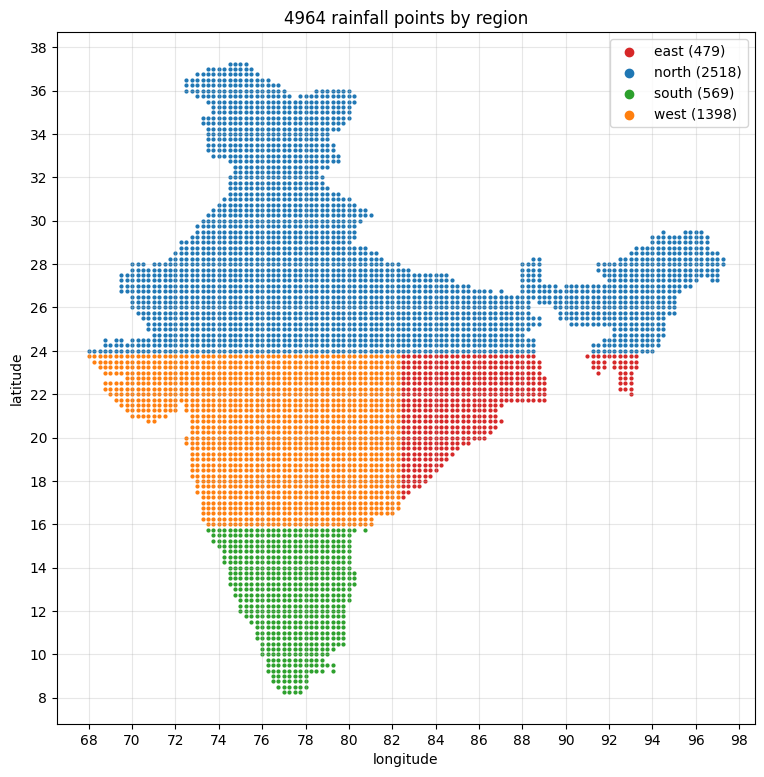

westmost: [np.float64(23.75), np.float64(68.0)]
eastmost: [np.float64(28.0), np.float64(97.25)]
northmost: [np.float64(37.25), np.float64(74.5)]
southmost: [np.float64(8.25), np.float64(77.0)]


In [7]:
import matplotlib.pyplot as plt

colors = {"north": "tab:blue", "west": "tab:orange", "south": "tab:green", "east": "tab:red"}

fig, ax = plt.subplots(figsize=(9, 10))
for reg, g in PTS.groupby("region"):
    ax.scatter(g.longitude, g.latitude, s=4, c=colors[reg], label=f"{reg} ({len(g)})")

ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
ax.set_title(f"{len(PTS)} rainfall points by region")
ax.set_xticks(range(68, 99, 2)); ax.set_yticks(range(8, 39, 2))
ax.grid(alpha=0.3); ax.set_aspect("equal")
ax.legend(markerscale=3, loc="upper right")
plt.show()

# extreme points in each direction, for reading the map
print("westmost:", PTS.loc[PTS.longitude.idxmin(), ["latitude", "longitude"]].tolist())
print("eastmost:", PTS.loc[PTS.longitude.idxmax(), ["latitude", "longitude"]].tolist())
print("northmost:", PTS.loc[PTS.latitude.idxmax(), ["latitude", "longitude"]].tolist())
print("southmost:", PTS.loc[PTS.latitude.idxmin(), ["latitude", "longitude"]].tolist())

In [8]:
df = load_year(2023)
df["key"] = point_key(df.latitude, df.longitude)

dates = pd.date_range("2023-01-01", "2023-12-31").strftime("%Y-%m-%d")
print("rows:", len(df), "| expected:", len(PTS) * len(dates))
print("duplicate (date, point) rows:", int(df.duplicated(["date", "key"]).sum()))

# dates with fewer than 4964 rows
per_date = df.groupby("date").size()
short_dates = per_date[per_date != len(PTS)]
print("\ndates with a short row count:", len(short_dates))
print(short_dates.to_string())

# exact missing (date, point) pairs
full = pd.MultiIndex.from_product([dates, PTS.key.values], names=["date", "key"])
have = pd.MultiIndex.from_frame(df[["date", "key"]])
missing = full.difference(have).to_frame(index=False)
missing = missing.merge(PTS[["key", "latitude", "longitude", "region"]], on="key")

print("\nmissing pairs:", len(missing))
print("distinct dates:", missing.date.nunique(), "| distinct points:", missing.key.nunique())
print("\nby region:\n", missing.region.value_counts().to_string())
print("\nby month:\n", missing.date.str.slice(5, 7).value_counts().sort_index().to_string())
print("\nfirst 20 missing pairs:")
print(missing.sort_values(["date", "latitude", "longitude"]).head(20).to_string(index=False))

# rainfall on the days around each missing date, to see if they look like real zero-rain days
if len(missing):
    d0 = missing.date.min()
    print("\nrain on the first missing date for points that do have data (summary):")
    print(df.loc[df.date == d0, "rainfall_mm"].describe().round(2).to_string())

rows: 1811781 | expected: 1811860
duplicate (date, point) rows: 0

dates with a short row count: 1
date
2023-10-12    4885

missing pairs: 79
distinct dates: 1 | distinct points: 79

by region:
 region
west     68
north    11

by month:
 date
10    79

first 20 missing pairs:
      date      key  latitude  longitude region
2023-10-12 21007000     21.00      70.00   west
2023-10-12 21007025     21.00      70.25   west
2023-10-12 21256975     21.25      69.75   west
2023-10-12 21257000     21.25      70.00   west
2023-10-12 21257025     21.25      70.25   west
2023-10-12 21506950     21.50      69.50   west
2023-10-12 21506975     21.50      69.75   west
2023-10-12 21507000     21.50      70.00   west
2023-10-12 21507025     21.50      70.25   west
2023-10-12 21756925     21.75      69.25   west
2023-10-12 21756950     21.75      69.50   west
2023-10-12 21756975     21.75      69.75   west
2023-10-12 21757000     21.75      70.00   west
2023-10-12 21757025     21.75      70.25   west
202

features: 37
CRS: EPSG:3857
columns: ['State_Name', 'geometry']
geometry types: {'Polygon': 29, 'MultiPolygon': 8}
invalid geometries: 1
converting to EPSG:4326

rows after join: 4964 | points: 4964
points matching more than one polygon: 0
points inside no polygon: 333

features and point counts:
                                  State_Name  n_points
0                          Andaman & Nicobar         0
1                                 Chandigarh         1
2   Daman and Diu and Dadra and Nagar Haveli         1
3                                      Delhi         3
4                                    Haryana        65
5                                  Jharkhand       114
6                                  Karnataka       253
7                                     Kerala        50
8                                Lakshadweep         0
9                             Madhya Pradesh       439
10                               Maharashtra       423
11                                    Odis

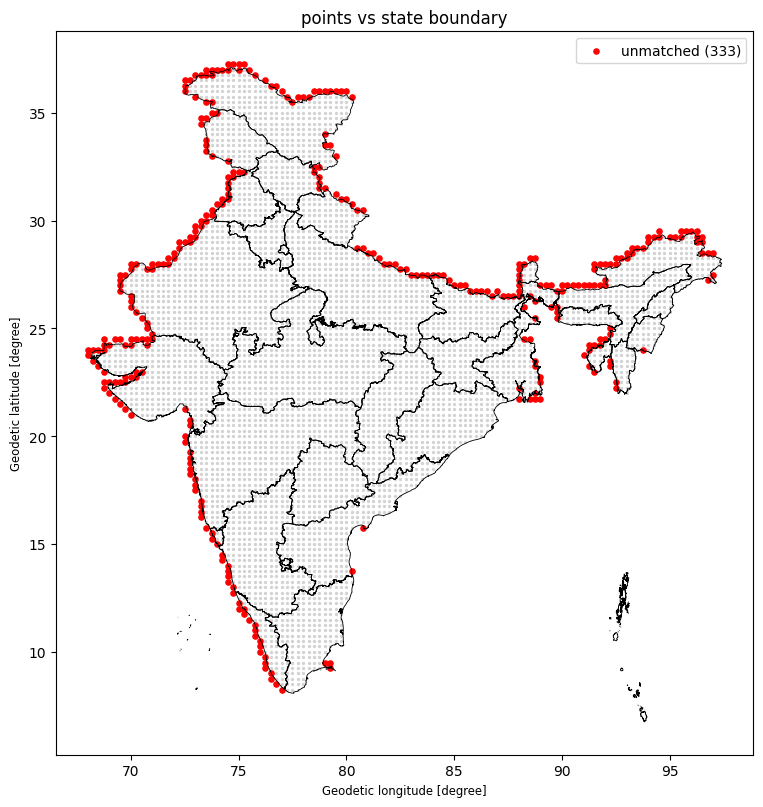

In [9]:
import geopandas as gpd
import matplotlib.pyplot as plt

SHP = ROOT / "data" / "map" / "India_State_Boundary.shp"
gdf = gpd.read_file(SHP)

print("features:", len(gdf))
print("CRS:", gdf.crs)
print("columns:", list(gdf.columns))
print("geometry types:", gdf.geom_type.value_counts().to_dict())
print("invalid geometries:", int((~gdf.is_valid).sum()))

if gdf.crs is None:
    raise SystemExit("No CRS in the .prj file. Paste this output and stop here.")
if gdf.crs.to_epsg() != 4326:
    print("converting to EPSG:4326")
    gdf = gdf.to_crs(4326)

# the 4964 points as geometry
pts_gdf = gpd.GeoDataFrame(
    PTS.copy(),
    geometry=gpd.points_from_xy(PTS.longitude, PTS.latitude),
    crs="EPSG:4326",
)

joined = gpd.sjoin(pts_gdf, gdf, how="left", predicate="within")
print("\nrows after join:", len(joined), "| points:", len(PTS))
print("points matching more than one polygon:", int(joined.key.duplicated(keep=False).sum()))

unmatched = joined[joined.index_right.isna()]
print("points inside no polygon:", len(unmatched))

# polygons with their point counts
gdf["n_points"] = joined.groupby("index_right").size().reindex(gdf.index).fillna(0).astype(int)
print("\nfeatures and point counts:")
print(gdf.drop(columns="geometry").to_string())

print("\nunmatched points (first 30):")
print(unmatched[["key", "latitude", "longitude", "region"]].head(30).to_string(index=False))

# map: boundaries, matched points in grey, unmatched in red
fig, ax = plt.subplots(figsize=(9, 10))
gdf.boundary.plot(ax=ax, linewidth=0.6, color="black")
ok = joined[joined.index_right.notna()]
ax.scatter(ok.longitude, ok.latitude, s=2, c="lightgrey")
ax.scatter(unmatched.longitude, unmatched.latitude, s=14, c="red",
           label=f"unmatched ({len(unmatched)})")
ax.set_aspect("equal"); ax.legend(); ax.set_title("points vs state boundary")
plt.show()

assigned by: {'within': 4631, 'nearest': 333}
nearest-state distance (approx km): median 10.6 | max 36.3
points further than 40 km from a state: 0

points per region:
 region
northwest          1633
central            1596
south_peninsula     880
east_northeast      855

points per state:
 state
Rajasthan                                   534
Madhya Pradesh                              439
Maharashtra                                 438
Uttar Pradesh                               357
Ladakh                                      307
Gujarat                                     304
Karnataka                                   261
Andhra Pradesh                              223
Odisha                                      216
Chhattishgarh                               189
Tamilnadu                                   173
Arunachal Pradesh                           158
Telengana                                   153
Bihar                                       151
West Bengal                    

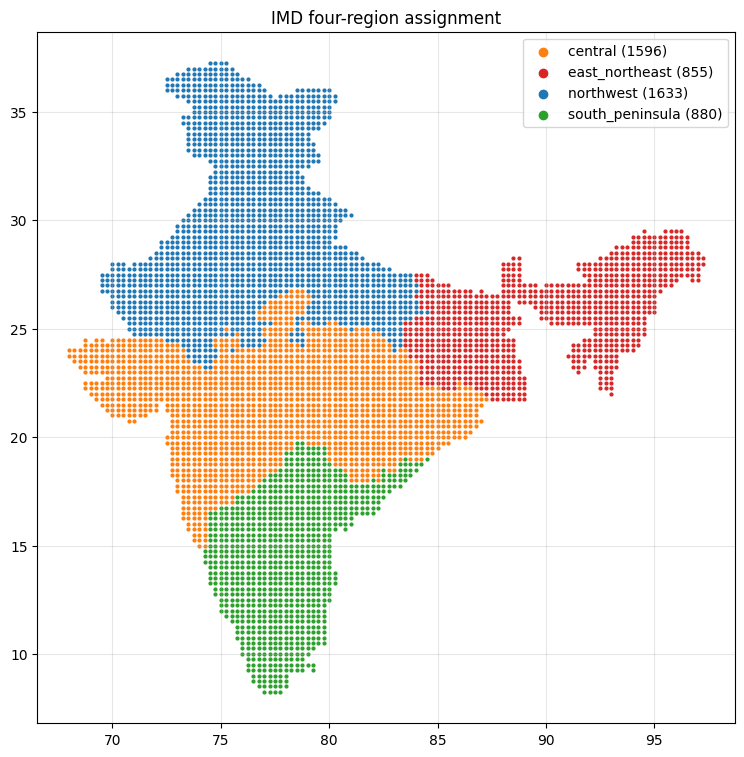

saved: ../data/processed/point_region_v2.csv


In [10]:
import geopandas as gpd
import matplotlib.pyplot as plt

REGION_OF_STATE = {}
for st in ["Jammu and Kashmir", "Ladakh", "Himachal Pradesh", "Punjab", "Haryana", "Delhi",
           "Uttarakhand", "Rajasthan", "Uttar Pradesh", "Chandigarh"]:
    REGION_OF_STATE[st] = "northwest"
for st in ["Madhya Pradesh", "Chhattishgarh", "Gujarat", "Maharashtra", "Odisha", "Goa",
           "Daman and Diu and Dadra and Nagar Haveli"]:
    REGION_OF_STATE[st] = "central"
for st in ["Andhra Pradesh", "Telengana", "Karnataka", "Kerala", "Tamilnadu", "Puducherry"]:
    REGION_OF_STATE[st] = "south_peninsula"
for st in ["Bihar", "Jharkhand", "West Bengal", "Sikkim", "Assam", "Arunachal Pradesh",
           "Nagaland", "Manipur", "Mizoram", "Tripura", "Meghalaya"]:
    REGION_OF_STATE[st] = "east_northeast"
SKIP = {"Andaman & Nicobar", "Lakshadweep"}

gdf = gpd.read_file(ROOT / "data" / "map" / "India_State_Boundary.shp").to_crs(3857)
unknown = set(gdf.State_Name) - set(REGION_OF_STATE) - SKIP
assert not unknown, f"unmapped state names: {unknown}"
gdf = gdf[~gdf.State_Name.isin(SKIP)].copy()
gdf["geometry"] = gdf.geometry.make_valid()
poly = gdf[["State_Name", "geometry"]]

pg = gpd.GeoDataFrame(PTS[["key", "latitude", "longitude"]].copy(),
                      geometry=gpd.points_from_xy(PTS.longitude, PTS.latitude),
                      crs=4326).to_crs(3857)

# 1. points inside a state
a = gpd.sjoin(pg, poly, how="left", predicate="within").drop(columns="index_right")
a = a.drop_duplicates("key")
inside = a[a.State_Name.notna()].copy()
inside["assigned_by"], inside["dist_km"] = "within", 0.0

# 2. the rest go to the nearest state (distance is approximate, in a flat projection)
miss = a[a.State_Name.isna()].drop(columns="State_Name")
b = gpd.sjoin_nearest(miss, poly, how="left", distance_col="dist_m").drop(columns="index_right")
b = b.drop_duplicates("key")
b["assigned_by"], b["dist_km"] = "nearest", b.dist_m / 1000

res = pd.concat([inside.drop(columns="geometry"), b.drop(columns=["geometry", "dist_m"])])
res = res.rename(columns={"State_Name": "state"})
res["region"] = res.state.map(REGION_OF_STATE)
res = PTS[["key"]].merge(res, on="key", how="left")

assert len(res) == len(PTS) == res.key.nunique(), "row count problem"
assert res.region.notna().all(), "points without a region"

print("assigned by:", res.assigned_by.value_counts().to_dict())
print("nearest-state distance (approx km): median", round(res[res.assigned_by == 'nearest'].dist_km.median(), 1),
      "| max", round(res.dist_km.max(), 1))
print("points further than 40 km from a state:", int((res.dist_km > 40).sum()))
print("\npoints per region:\n", res.region.value_counts().to_string())
print("\npoints per state:\n", res.state.value_counts().to_string())

# old rule vs new rule
print("\nold region (rows) vs new region (columns):")
print(pd.crosstab(PTS.set_index("key").region.reindex(res.key).values, res.region.values))

# map
colors = {"northwest": "tab:blue", "central": "tab:orange",
          "south_peninsula": "tab:green", "east_northeast": "tab:red"}
fig, ax = plt.subplots(figsize=(9, 10))
for reg, g in res.merge(PTS[["key", "latitude", "longitude"]], on="key",
                        suffixes=("", "_p")).groupby("region"):
    ax.scatter(g.longitude, g.latitude, s=4, c=colors[reg], label=f"{reg} ({len(g)})")
ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.legend(markerscale=3)
ax.set_title("IMD four-region assignment")
plt.show()

res.to_csv(PROCESSED / "point_region_v2.csv", index=False)
print("saved:", PROCESSED / "point_region_v2.csv")

In [11]:
idx_all = INDICES.sort_values("date").reset_index(drop=True).copy()
idx_all["nino_3m"] = idx_all.nino34.rolling(3, center=True, min_periods=3).mean()

idx = idx_all[(idx_all.date >= f"{START_YEAR}-01-01") & (idx_all.date <= f"{END_YEAR}-12-01")].copy()
idx["year"] = idx.date.dt.year
idx["month"] = idx.date.dt.month
idx["split"] = idx.year.map(split_of)
idx["enso"] = np.where(idx.nino_3m >= 0.5, "El Nino", np.where(idx.nino_3m <= -0.5, "La Nina", "neutral"))
idx["iod"] = np.where(idx.dmi >= 0.4, "positive", np.where(idx.dmi <= -0.4, "negative", "neutral"))

order = ["train", "val", "test"]
print("months per split:", idx.split.value_counts().reindex(order).to_dict(), "(expected 1224 / 132 / 144)")
print("years per split:", idx.groupby("split").year.agg(["min", "max", "nunique"]).reindex(order).to_dict("index"))
print("rows with no split:", int(idx.split.isna().sum()))

for col in ["enso", "iod"]:
    print(f"\n== {col}: months ==")
    print(pd.crosstab(idx.split, idx[col]).reindex(order).to_string())
    print(f"== {col}: % of months ==")
    print((pd.crosstab(idx.split, idx[col], normalize="index") * 100).round(1).reindex(order).to_string())

jj = idx[idx.month.between(6, 9)]
print("\n== monsoon months only (Jun-Sep): ENSO ==")
print(pd.crosstab(jj.split, jj.enso).reindex(order).to_string())
print("== monsoon months only (Jun-Sep): IOD ==")
print(pd.crosstab(jj.split, jj.iod).reindex(order).to_string())

print("\n== Nino 3.4 and DMI summary by split ==")
print(idx.groupby("split")[["nino34", "dmi"]].agg(["mean", "std", "min", "max"]).round(2).reindex(order).to_string())

# years with a clear El Nino or La Nina in the monsoon season (>= 3 of 4 months)
yr = jj.groupby(["year", "split"]).enso.agg(
    lambda s: "El Nino" if (s == "El Nino").sum() >= 3 else ("La Nina" if (s == "La Nina").sum() >= 3 else "neutral")
).reset_index()
print("\nmonsoon-season ENSO years per split:")
print(pd.crosstab(yr.split, yr.enso).reindex(order).to_string())
for s in ["val", "test"]:
    print(f"{s} El Nino years:", yr[(yr.split == s) & (yr.enso == "El Nino")].year.tolist(),
          "| La Nina years:", yr[(yr.split == s) & (yr.enso == "La Nina")].year.tolist())

months per split: {'train': 1224, 'val': 132, 'test': 144} (expected 1224 / 132 / 144)
years per split: {'train': {'min': 1901, 'max': 2002, 'nunique': 102}, 'val': {'min': 2003, 'max': 2013, 'nunique': 11}, 'test': {'min': 2014, 'max': 2025, 'nunique': 12}}
rows with no split: 0

== enso: months ==
enso   El Nino  La Nina  neutral
split                           
train      248      332      644
val         23       38       71
test        45       38       61
== enso: % of months ==
enso   El Nino  La Nina  neutral
split                           
train     20.3     27.1     52.6
val       17.4     28.8     53.8
test      31.2     26.4     42.4

== iod: months ==
iod    negative  neutral  positive
split                             
train       395      794        35
val           9      116         7
test          8      105        31
== iod: % of months ==
iod    negative  neutral  positive
split                             
train      32.3     64.9       2.9
val         6.8     87.

planned split:
Splits: train 1901-2002, val 2003-2013, test 2014-2025.

Sizes. Train is 102 years (1,224 months), val is 11 years (132 months) and test is 12 years (144 months). Train is about 82% of the 1,500 months, which is the roadmap’s “more training months” aim.

ENSO and IOD coverage.

Train has the strong El Niño years 1982-83 and 1997-98, and ends with the 2002 drought year.
Val has the 2009-10 El Niño (a drought year in India) and the strong 2010-11 La Niña.
Test has the 2015-16 and 2023-24 El Niños, the 2020-22 run of La Niña years, and the strong positive IOD of 2019.

So val and test each contain both warm and cold ENSO phases, and the test period is not just one kind of year.

The buffer rule drops the three origin months before each boundary, because their target windows cross it: Oct-Dec 2002 and Oct-Dec 2013 to avoid leakage into further splits.

The ENSO split is reasonable: El Nino months are 20% of train, 17% of val and 31% of test, and La Nina months are 27%, 29% and 26%.

Level drift: mean DMI is -0.26 in train, -0.01 in val and +0.11 in test, about one standard deviation from train to test.

Phase counts: train has 395 negative months and only 35 positive. Val has just 9 negative and 7 positive. Test has 31 positive. The model will learn almost entirely from negative and neutral IOD and will be tested in a different regime.

**That means val and test can say little about the IOD terms, and the DMI level shift is a data drift issue**

In [13]:
# code to generate monthly values
t0 = time.time()
parts = []

for yr in YEARS:
    df = load_year(yr)
    key = point_key(df.latitude, df.longitude)
    month = df["date"].str.slice(5, 7).astype("int8").values

    g = (pd.DataFrame({"key": key, "month": month,
                       "rain": df.rainfall_mm.astype("float64").values})
           .groupby(["key", "month"], sort=True)["rain"]
           .agg(rain_mm="sum", days_present="size")
           .reset_index())

    g["year"] = np.int16(yr)
    g["days_expected"] = g.month.map(lambda m: calendar.monthrange(yr, m)[1]).astype("int8")

    # gap rule: any point-month with missing days gets a missing total
    g.loc[g.days_present != g.days_expected, "rain_mm"] = np.nan

    g["rain_mm"] = g.rain_mm.astype("float32")
    g["days_present"] = g.days_present.astype("int8")
    g["key"] = g.key.astype("int64")
    g["month"] = g.month.astype("int8")
    parts.append(g[["key", "year", "month", "rain_mm", "days_present", "days_expected"]])
    del df, key, month, g

monthly = pd.concat(parts, ignore_index=True)
del parts
print("time (min):", round((time.time() - t0) / 60, 1))

# ---- checks (print only) ----
print("\nrows:", len(monthly), "| expected:", len(PTS) * len(YEARS) * 12)
print("points:", monthly.key.nunique(), "| years:", monthly.year.nunique())
print("keys not in PTS:", int((~monthly.key.isin(PTS.key)).sum()))
print("duplicate (key, year, month):", int(monthly.duplicated(["key", "year", "month"]).sum()))
print("missing totals:", int(monthly.rain_mm.isna().sum()), "(expected 79)")
print(monthly[monthly.rain_mm.isna()].groupby(["year", "month"]).size().to_string())
print("negative totals:", int((monthly.rain_mm < 0).sum()))
print("days_present != days_expected:", int((monthly.days_present != monthly.days_expected).sum()))

# spot check: one point-month recomputed straight from the daily file
chk = load_year(2010)
chk["key"] = point_key(chk.latitude, chk.longitude)
k0 = int(PTS.key.iloc[2000])
direct = float(chk[(chk.key == k0) & (chk.date.str.slice(5, 7) == "07")].rainfall_mm.astype("float64").sum())
stored = float(monthly[(monthly.key == k0) & (monthly.year == 2010) & (monthly.month == 7)].rain_mm.iloc[0])
print(f"\nspot check key {k0}, Jul 2010: direct {direct:.3f} | stored {stored:.3f}")
del chk

# sanity: all-India mean monthly total and mean annual total by decade
print("\nmean monthly total by calendar month (mm, all points, all years):")
print(monthly.groupby("month").rain_mm.mean().round(1).to_string())
ann = monthly.groupby(["key", "year"]).rain_mm.sum(min_count=12).reset_index()
print("\nmean annual total by decade (mm):")
print(ann.groupby((ann.year // 10) * 10).rain_mm.mean().round(0).to_string())
print("\nmax monthly total (mm):", float(monthly.rain_mm.max()))

# ---- save (new name, interim is ignored by Git and DVC) ----
out = INTERIM / "monthly_rain_v2.parquet"
monthly.to_parquet(out, index=False)
print("\nsaved:", out, "| size MB:", round(out.stat().st_size / 1e6, 1))

time (min): 1.4

rows: 7446000 | expected: 7446000
points: 4964 | years: 125
keys not in PTS: 0
duplicate (key, year, month): 0
missing totals: 79 (expected 79)
year  month
2023  10       79
negative totals: 0
days_present != days_expected: 79

spot check key 22508850, Jul 2010: direct 226.227 | stored 226.227

mean monthly total by calendar month (mm, all points, all years):
month
1      18.000000
2      21.299999
3      27.299999
4      39.099998
5      63.299999
6     162.699997
7     281.100006
8     247.500000
9     167.199997
10     73.099998
11     27.900000
12     14.400000

mean annual total by decade (mm):
year
1900    1058.0
1910    1137.0
1920    1114.0
1930    1183.0
1940    1203.0
1950    1169.0
1960    1086.0
1970    1146.0
1980    1161.0
1990    1185.0
2000    1089.0
2010    1130.0
2020    1221.0

max monthly total (mm): 6881.453125

saved: ../data/interim/monthly_rain_v2.parquet | size MB: 32.0


In [14]:
#inspecting top 10 monthly totals
import numpy as np, pandas as pd, time
t0 = time.time()

df = pd.read_parquet("../data/interim/monthly_rain_v2.parquet")
print("columns:", df.columns.tolist())

known = {"key","year","month","days_present","days_expected","lat","lon",
         "latitude","longitude","state","region"}
cand = [c for c in df.columns if c not in known and pd.api.types.is_float_dtype(df[c])]
assert len(cand) == 1, f"cannot pick the total column, candidates: {cand}"
TOT = cand[0]
print("total column:", TOT)

print("\ntop 10 monthly totals:")
print(df.nlargest(10, TOT).to_string(index=False))

df = df.sort_values(["key","year","month"]).reset_index(drop=True)
P = df["key"].nunique()
assert len(df) == P*1500
X = df[TOT].to_numpy("float64").reshape(P, 1500)
assert (df["year"].to_numpy().reshape(P,1500)[:,0] == 1901).all()

# 3-month target: months t+1..t+3 (missing if any month is missing)
W = np.full((P,1500), np.nan)
W[:, :1497] = X[:,1:1498] + X[:,2:1499] + X[:,3:1500]
W3 = W.reshape(P,125,12)                      # point, origin year, origin month (0=Jan)

yrs = np.arange(1901, 2026)[:,None]           # (125,1)
mos = np.arange(12)[None,:]                   # (1,12)
split = np.where(yrs<=2002,"train",np.where(yrs<=2013,"val","test"))
split = np.broadcast_to(split,(125,12))
buffer = np.isin(yrs,[2002,2013,2025]) & (mos>=9)   # origins Oct-Dec before each boundary
buffer = np.broadcast_to(buffer,(125,12))
train_m = (split=="train") & ~buffer

# normal per point and origin month (window start month = origin month + 1), train only
mu = np.full((P,12),np.nan); sd = np.full((P,12),np.nan); n = np.zeros((P,12),int)
for m in range(12):
    v = W3[:, train_m[:,m], m]
    mu[:,m] = np.nanmean(v,axis=1)
    sd[:,m] = np.nanstd(v,axis=1,ddof=1)
    n[:,m]  = np.sum(~np.isnan(v),axis=1)
print("\ntrain years per point and window start month: min", n.min(), "| median", int(np.median(n)))

# sd distribution
print("\nsd of 3-month totals (mm), all point x window-start-month cells:")
print(pd.Series(sd.ravel()).describe(percentiles=[.001,.01,.05,.25,.5,.75]).round(2).to_string())
print("cells with sd == 0:", int((sd==0).sum()), "of", sd.size)

rows = []
for m in range(12):
    s = sd[:,m]
    rows.append({"window_start_month": (m+1)%12+1, "min": s.min(),
                 "p1": np.percentile(s,1), "p5": np.percentile(s,5),
                 "p25": np.percentile(s,25), "median": np.median(s)})
print("\nsd by window start month (mm):")
print(pd.DataFrame(rows).sort_values("window_start_month").round(2).to_string(index=False))

# candidate floors
valid = ~np.isnan(W3) & ~buffer[None,:,:]
out = []
for fl in [1e-6, 1, 2, 5, 10, 15, 20, 30, 50]:
    sd_eff = np.maximum(sd, fl)
    z = (W3 - mu[:,None,:]) / sd_eff[:,None,:]
    floored_cell = (sd < fl)
    r = {"floor_mm": fl, "cells_floored_%": round(100*floored_cell.mean(),2)}
    for sp in ["train","val","test"]:
        msk = valid & (split==sp)[None,:,:]
        fr = floored_cell[:,None,:] & msk
        r[f"{sp}_rows"] = int(msk.sum())
        r[f"{sp}_floored_%"] = round(100*fr.sum()/msk.sum(),2)
        r[f"{sp}_|z|>6"] = int((np.abs(z[msk])>6).sum())
    out.append(r)
print("\nfloor candidates:")
print(pd.DataFrame(out).to_string(index=False))
print("\ntime (min):", round((time.time()-t0)/60,1))

columns: ['key', 'year', 'month', 'rain_mm', 'days_present', 'days_expected']
total column: rain_mm

top 10 monthly totals:
     key  year  month     rain_mm  days_present  days_expected
25509175  1984      7 6881.453125            31             31
25259125  1974      7 6149.217773            31             31
25259125  1982      6 5799.305176            30             30
25259125  1982      7 5639.292969            31             31
25259150  1974      7 5615.195312            31             31
25259175  1984      7 5395.261230            31             31
25259125  2022      6 5369.678711            30             30
25259075  2022      6 5136.124512            30             30
25259100  2022      6 5086.092285            30             30
25259150  2022      6 5016.550781            30             30

train years per point and window start month: min 101 | median 102

sd of 3-month totals (mm), all point x window-start-month cells:
count    59568.00
mean       123.82
std        12

Floor evidence

Every cell has 101 to 102 train years behind its mean and sd, which is good.
180 cells (0.30%) have sd exactly 0. These are dry-season windows where it never rained in train years, probably in the northwest. They need a floor, or z divides by zero.
Floors from 1 to 5 mm only touch those 0.32% of cells.
At 10 mm, 1.86% of cells are floored. This starts to catch real low-variance cells, since the 1st percentile of sd in dry windows is about 6 to 7 mm.
At 15 mm and above, 4.5% or more of cells are floored, which squeezes real variability. Larger floors also cut the |z| > 6 counts only because they shrink z, not because the data improved.

Final floor pick: 5 mm. It fixes the zero-sd cells and nothing else, and it keeps the same value as v1. A bigger floor would hide real variability to remove a few extreme rows, and the |z| > 6 filter already handles those.
Later try: 10 mm next reasonable choice(dryer regions)

In [21]:
#consolidation of v2 dataset
import numpy as np, pandas as pd, json, time
from pathlib import Path
t0 = time.time()

SD_FLOOR = 5.0
TRAIN_END, VAL_END = 2002, 2013
OUT_NAME = "rain_v2_3month"
OUT_DIR= PROCESSED
mdf = pd.read_parquet(INTERIM / "monthly_rain_v2.parquet")

# ---------- monthly rain ----------
mdf = pd.read_parquet("../data/interim/monthly_rain_v2.parquet")
mdf = mdf.sort_values(["key", "year", "month"]).reset_index(drop=True)
keys = np.sort(mdf["key"].unique())
P = len(keys)
assert len(mdf) == P * 1500
assert (mdf["year"].to_numpy().reshape(P, 1500)[:, 0] == 1901).all()
assert (mdf["month"].to_numpy().reshape(P, 1500)[:, :12] == np.arange(1, 13)).all()
X = mdf["rain_mm"].to_numpy("float64").reshape(P, 1500)


# ---------- points and regions ----------
pts = PTS.set_index("key").loc[keys]
assert pts["region"].notna().all() and pts["state"].notna().all(), "missing region or state"
assert set(pts["region"].unique()) == set(REGIONS), pts["region"].unique()
print("regions:", REGIONS, "| points:", len(pts))
lat = pts["latitude"].to_numpy("float32"); lon = pts["longitude"].to_numpy("float32")
state_cat = pd.Categorical(pts["state"]); region_cat = pd.Categorical(pts["region"], categories=REGIONS)

# ---------- Nino 3.4 and DMI ----------
def idx_series(col):
    s = INDICES.set_index("date")[col]
    s.index = s.index.to_period("M")
    s = s[~s.index.duplicated()]
    s = s.reindex(pd.period_range("1901-01", "2025-12", freq="M"))
    assert len(s) == 1500 and s.isna().sum() == 0, f"{col}: {s.isna().sum()} missing months"
    return s.to_numpy("float64")

NINO = idx_series("nino34")
DMI = idx_series("dmi")
print("nino34 first/last:", NINO[0], NINO[-1], "| dmi first/last:", DMI[0], DMI[-1])

# ---------- calendar, splits, buffer ----------
years = np.arange(1901, 2026)[:, None]; mos = np.arange(12)[None, :]
split_code = np.where(years <= TRAIN_END, 0, np.where(years <= VAL_END, 1, 2))
split_code = np.broadcast_to(split_code, (125, 12))
buffer = np.broadcast_to(np.isin(years, [TRAIN_END, VAL_END, 2025]) & (mos >= 9), (125, 12))
train_m = (split_code == 0) & ~buffer
ntr = TRAIN_END - 1901 + 1                         # 102 train years

# ---------- monthly normal (for rain lags), train years only ----------
Xy = X.reshape(P, 125, 12)
mu_m = np.nanmean(Xy[:, :ntr, :], axis=1)
sd_m_raw = np.nanstd(Xy[:, :ntr, :], axis=1, ddof=1)
sd_m = np.maximum(sd_m_raw, SD_FLOOR)
Z = ((Xy - mu_m[:, None, :]) / sd_m[:, None, :]).reshape(P, 1500).astype("float32")

def shift(A, k):
    if k == 0: return A
    B = np.full_like(A, np.nan); B[:, k:] = A[:, :-k]; return B
def shift1(a, k):
    b = np.full_like(a, np.nan)
    if k == 0: return a.copy()
    b[k:] = a[:-k]; return b

rain_z_t = Z
rain_z_lag1 = shift(Z, 1)
S = Z.copy()
roll3 = None
for k in range(1, 6):
    S = S + shift(Z, k)
    if k == 2: roll3 = S / 3
roll6 = S / 6
del S

# ---------- 3-month target and its normal (per point and origin month), train only ----------
W = np.full((P, 1500), np.nan)
W[:, :1497] = X[:, 1:1498] + X[:, 2:1499] + X[:, 3:1500]
W3 = W.reshape(P, 125, 12)
mu_w = np.full((P, 12), np.nan); sd_w_raw = np.full((P, 12), np.nan)
for m in range(12):
    v = W3[:, train_m[:, m], m]
    mu_w[:, m] = np.nanmean(v, axis=1); sd_w_raw[:, m] = np.nanstd(v, axis=1, ddof=1)
sd_w = np.maximum(sd_w_raw, SD_FLOOR)
tmean = np.broadcast_to(mu_w[:, None, :], (P, 125, 12)).reshape(P, 1500)
tsd = np.broadcast_to(sd_w[:, None, :], (P, 125, 12)).reshape(P, 1500)
tanom = W - tmean
tz = tanom / tsd

# ---------- index features (1D, same for all points) ----------
def idx_feats(a, p, with_chg=False):
    f = {f"{p}_t": a, f"{p}_lag1": shift1(a, 1), f"{p}_lag2": shift1(a, 2), f"{p}_lag3": shift1(a, 3),
         f"{p}_mean3": (a + shift1(a, 1) + shift1(a, 2)) / 3}
    if with_chg: f[f"{p}_chg3"] = a - shift1(a, 3)
    return f
IDX = {**idx_feats(NINO, "nino34", True), **idx_feats(DMI, "dmi")}

# ---------- time columns ----------
yr1 = np.repeat(np.arange(1901, 2026), 12); mo1 = np.tile(np.arange(1, 13), 125)
sp1 = split_code.ravel(); buf1 = buffer.ravel()
B = lambda a1: np.broadcast_to(a1[None, :], (P, 1500))   # 1D time array to (P,1500)
Bp = lambda a1: np.broadcast_to(a1[:, None], (P, 1500))  # 1D point array to (P,1500)

feat_arrays = {"rain_z_t": rain_z_t, "rain_z_lag1": rain_z_lag1, "rain_z_roll3": roll3, "rain_z_roll6": roll6}
for k, a in IDX.items(): feat_arrays[k] = B(a.astype("float32"))

# ---------- row selection ----------
fnan = np.zeros((P, 1500), bool)
for a in feat_arrays.values(): fnan |= np.isnan(a)
tnan = np.isnan(tz)
bufm = B(buf1)
keep = ~fnan & ~tnan & ~bufm
print("\nrow drops (overlapping reasons):")
print("  buffer rows:", int(bufm.sum()), "| target missing:", int(tnan.sum()), "| input missing:", int(fnan.sum()))
print("  total grid:", P * 1500, "| kept:", int(keep.sum()))

# ---------- assemble ----------
cols = {}
cols["key"] = Bp(keys)[keep]
cols["state"] = pd.Categorical.from_codes(Bp(state_cat.codes.astype("int16"))[keep], state_cat.categories)
cols["region"] = pd.Categorical.from_codes(Bp(region_cat.codes.astype("int8"))[keep], REGIONS)
cols["year"] = B(yr1)[keep].astype("int16"); cols["month"] = B(mo1)[keep].astype("int8")
cols["split"] = pd.Categorical.from_codes(B(sp1.astype("int8"))[keep], ["train", "val", "test"])
cols["target_mm"] = W[keep].astype("float32")
cols["target_mean"] = tmean[keep].astype("float32")
cols["target_sd"] = tsd[keep].astype("float32")
cols["target_anom_mm"] = tanom[keep].astype("float32")
cols["target_z"] = tz[keep].astype("float32")
cols["lat"] = Bp(lat)[keep]; cols["lon"] = Bp(lon)[keep]
cols["month_sin"] = B(np.sin(2*np.pi*mo1/12).astype("float32"))[keep]
cols["month_cos"] = B(np.cos(2*np.pi*mo1/12).astype("float32"))[keep]
rc = Bp(region_cat.codes.astype("int8"))[keep]
for i, r in enumerate(REGIONS):
    cols[f"region_{r}"] = (rc == i).astype("int8")
for k, a in feat_arrays.items(): cols[k] = a[keep].astype("float32")
df = pd.DataFrame(cols)
INPUTS = ["lat", "lon", "month_sin", "month_cos"] + [f"region_{r}" for r in REGIONS] + list(feat_arrays.keys())
print("rows:", len(df), "| columns:", df.shape[1], "| inputs:", len(INPUTS))

# ---------- checks ----------
print("\nCHECKS")
print("points:", df["key"].nunique(), "(expected", P, ")")
print("rows by split:", df["split"].value_counts().to_dict())
ym = df["year"].astype(int) * 100 + df["month"].astype(int)
print("origin range by split (yyyymm):")
print(df.assign(ym=ym).groupby("split", observed=True)["ym"].agg(["min", "max"]).to_string())

nan_in = int(df[INPUTS].isna().sum().sum()); print("NaN in input columns:", nan_in); assert nan_in == 0
assert df["target_z"].notna().all()

t_idx = df["year"].to_numpy().astype(int) * 12 + df["month"].to_numpy().astype(int)
kk = df["key"].to_numpy()
same = (kk[1:] == kk[:-1]) & (np.diff(t_idx) == 1)
lag_ok = np.allclose(df["rain_z_lag1"].to_numpy()[1:][same], df["rain_z_t"].to_numpy()[:-1][same], atol=1e-5)
print("lag_1 equals previous month's z on", int(same.sum()), "consecutive pairs:", lag_ok); assert lag_ok

g = df.groupby(["key", "month"], observed=True)["target_sd"].agg(["min", "max"])
sd_const = float((g["max"] - g["min"]).abs().max()); print("max sd spread per point and month:", sd_const); assert sd_const < 1e-4

rec = np.abs((df["target_mm"] - df["target_mean"]) / df["target_sd"] - df["target_z"]).max()
print("max |recomputed z - target_z|:", float(rec)); assert rec < 1e-3

pos = (df["year"].to_numpy().astype(int) - 1901) * 12 + df["month"].to_numpy().astype(int) - 1
rng = np.random.default_rng(0); samp = rng.choice(len(df), 200000, replace=False)
base = {"nino34": NINO, "dmi": DMI}
p = pos[samp]
for k in IDX:
    name, kind = k.split("_", 1)
    a0 = base[name]
    if kind == "t":            exp = a0[p]
    elif kind.startswith("lag"): exp = a0[p - int(kind[3:])]
    elif kind == "mean3":      exp = (a0[p] + a0[p - 1] + a0[p - 2]) / 3
    elif kind == "chg3":       exp = a0[p] - a0[p - 3]
    assert np.allclose(df[k].to_numpy()[samp], exp, atol=1e-5), k
print("index features match the base series (t, lags 1-3, mean3, chg3): True")

lut = mdf.set_index(["key", "year", "month"])["rain_mm"]
ok = True
for i in rng.choice(len(df), 300, replace=False):
    y, m, k0 = int(df["year"].iat[i]), int(df["month"].iat[i]), df["key"].iat[i]
    tot = 0.0
    for j in (1, 2, 3):
        mm = m + j; yy = y + (mm - 1) // 12; mm = (mm - 1) % 12 + 1
        tot += float(lut.loc[(k0, yy, mm)])
    ok &= abs(tot - float(df["target_mm"].iat[i])) < 0.05
    y1, m1 = y, m
    zt = (float(lut.loc[(k0, y1, m1)]) - mu_m[np.searchsorted(keys, k0), m1 - 1]) / sd_m[np.searchsorted(keys, k0), m1 - 1]
    ok &= abs(zt - float(df["rain_z_t"].iat[i])) < 1e-3
print("target is the sum of months t+1..t+3 and rain_z_t uses month t (300 random rows):", bool(ok)); assert ok

tr = df[df["split"] == "train"]["target_z"]
print("train target_z mean/std:", round(float(tr.mean()), 4), round(float(tr.std()), 4))
for sp in ["train", "val", "test"]:
    z = df.loc[df["split"] == sp, "target_z"]
    print(f"{sp}: rows {len(z)} | mean {z.mean():.3f} | std {z.std():.3f} | |z|>6: {int((z.abs() > 6).sum())}")

# ---------- save ----------
OUT_DIR.mkdir(parents=True, exist_ok=True)
pq = OUT_DIR / f"{OUT_NAME}_dataset.parquet"; cs = OUT_DIR / f"{OUT_NAME}_dataset.csv"
assert not pq.exists() and not cs.exists(), "output already exists, pick a new name"
df.to_parquet(pq, index=False)
print("\nsaved:", pq, "| MB:", round(pq.stat().st_size / 1e6))

nrm = pd.DataFrame({"key": np.repeat(keys, 12), "origin_month": np.tile(np.arange(1, 13), P),
                    "month_mean_mm": mu_m.ravel(), "month_sd_mm": sd_m.ravel(),
                    "target_mean_mm": mu_w.ravel(), "target_sd_mm": sd_w.ravel()})
nrm.to_parquet(OUT_DIR / f"{OUT_NAME}_normals.parquet", index=False)

meta = {"inputs": INPUTS, "target": "target_z", "target_extra": ["target_mm", "target_mean", "target_sd", "target_anom_mm"],
        "id_columns": ["key", "state", "region", "year", "month", "split"],
        "params": {"sd_floor_mm": SD_FLOOR, "train_end": TRAIN_END, "val_end": VAL_END,
                   "target_window": "months t+1..t+3", "region_rule": "IMD 4 regions by state",
                   "normal_years": "1901-2002", "points": int(P)}}
json.dump(meta, open(OUT_DIR / f"{OUT_NAME}_feature_list.json", "w"), indent=2)
print("saved normals and feature list")

print("writing csv (slow)...")
df.to_csv(cs, index=False, float_format="%.4f")
print("saved:", cs, "| MB:", round(cs.stat().st_size / 1e6))
print("time (min):", round((time.time() - t0) / 60, 1))

regions: ['central', 'east_northeast', 'northwest', 'south_peninsula'] | points: 4964
nino34 first/last: 0.82 -0.49 | dmi first/last: -0.541 -0.017

row drops (overlapping reasons):
  buffer rows: 44676 | target missing: 15129 | input missing: 25294
  total grid: 7446000 | kept: 7375793
rows: 7375793 | columns: 34 | inputs: 23

CHECKS
points: 4964 (expected 4964 )
rows by split: {'train': 6036224, 'test': 699213, 'val': 640356}
origin range by split (yyyymm):
          min     max
split                
train  190106  200209
val    200301  201309
test   201401  202509
NaN in input columns: 0
lag_1 equals previous month's z on 7360822 consecutive pairs: True
max sd spread per point and month: 0.0
max |recomputed z - target_z|: 6.103515625e-05
index features match the base series (t, lags 1-3, mean3, chg3): True
target is the sum of months t+1..t+3 and rain_z_t uses month t (300 random rows): True
train target_z mean/std: 0.0009 0.994
train: rows 6036224 | mean 0.001 | std 0.994 | |z|>6: 

- Train target_z std is 0.994, as it should be.
- Val std is 3.87 and test std is 5.82.
- But the |z|>6 counts are small (2,281 val, 1,953 test out of about 650,000 rows each).
- So a few rows must have very large z, maybe 50 or more. These will dominate MSE skill in val and test.
- Likely cause: dry places in the dry season. Train sd is near the 5 mm floor, then a normal rain event gives a huge z.
- Test mean z is +0.207, so test is wetter than train on average (maybe also drift).

In [22]:
import pandas as pd

cols = ["key", "region", "year", "month", "split",
        "target_z", "target_mm", "target_mean", "target_sd"]
df = pd.read_parquet(PROCESSED / "rain_v2_3month_dataset.parquet", columns=cols)
df["abs_z"] = df["target_z"].abs()
FLOOR = 5.0

def z_check(d, name):
    print(f"\n===== {name} | rows {len(d)} =====")
    print("max |z|:", round(d["abs_z"].max(), 1))
    q = d["abs_z"].quantile([0.5, 0.9, 0.99, 0.999, 0.9999]).round(2)
    print("|z| quantiles 50/90/99/99.9/99.99:", q.tolist())

    big = d["abs_z"] > 6
    sq = d["target_z"] ** 2
    print("rows with |z|>6:", int(big.sum()),
          "| share of total squared z from them:", round(float(sq[big].sum() / sq.sum()), 3))

    at_floor = d["target_sd"] <= FLOOR + 1e-6
    print("rows with target_sd at the floor:", int(at_floor.sum()),
          "| of the |z|>6 rows at the floor:", int((big & at_floor).sum()))

    print("\ntop 20 rows by |z|:")
    top = d.nlargest(20, "abs_z")[["key", "region", "year", "month",
                                   "target_mm", "target_mean", "target_sd", "target_z"]]
    print(top.round(2).to_string(index=False))

    print("\n|z|>6 by region:")
    print(d[big].groupby("region").size().to_string())
    print("\n|z|>6 by origin month:")
    print(d[big].groupby("month").size().to_string())
    print("\n|z|>6 by year (top 5):")
    print(d[big].groupby("year").size().sort_values(ascending=False).head(5).to_string())

z_check(df[df["split"] == "val"], "val")
z_check(df[df["split"] == "test"], "test")


===== val | rows 640356 =====
max |z|: 366.3
|z| quantiles 50/90/99/99.9/99.99: [0.66, 1.66, 4.01, 10.52, 236.85]
rows with |z|>6: 2281 | share of total squared z from them: 0.922
rows with target_sd at the floor: 2035 | of the |z|>6 rows at the floor: 265

top 20 rows by |z|:
     key         region  year  month   target_mm  target_mean  target_sd   target_z
22509275 east_northeast  2007      5 1831.599976          0.0        5.0 366.320007
22259275 east_northeast  2007      5 1776.319946          0.0        5.0 355.260010
22009300 east_northeast  2007      5 1769.160034          0.0        5.0 353.829987
22259300 east_northeast  2007      5 1738.260010          0.0        5.0 347.649994
22509275 east_northeast  2007      6 1720.449951          0.0        5.0 344.089996
22509300 east_northeast  2007      5 1711.189941          0.0        5.0 342.239990
22259275 east_northeast  2007      6 1687.380005          0.0        5.0 337.480011
22009300 east_northeast  2007      6 1682.579956 

/tmp/ipykernel_12191/194339385.py:30: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(d[big].groupby("region").size().to_string())
/tmp/ipykernel_12191/194339385.py:30: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(d[big].groupby("region").size().to_string())


the train split mean z is not very high implying that for the same above points experiencing high target z values during the years after 2002.. rain values are unusually low in the train split before years 2002.. however the identified coordinates point to regions in mizoram during the months of july.. therefore less rain are logically not possible.. hence the below code for inspection to check for abnormal rain = 0mm values throught years for particular locations 

In [23]:
#inspecting above points in the train set due to unusually high z on the validation and test splits 
import pandas as pd

m = pd.read_parquet(INTERIM / "monthly_rain_v2.parquet",
                    columns=["key", "year", "month", "rain_mm"])
KEYS = [22009300, 22259275, 22259300, 22509275, 22509300]

# 1. The 5 points: annual total, averaged in 10-year blocks, train only and after
ann = m.groupby(["key", "year"], observed=True)["rain_mm"].sum().reset_index()
five = ann[ann["key"].isin(KEYS)].pivot(index="year", columns="key", values="rain_mm")
print("5 points, annual total (mm), mean per 10-year block:")
print(five.groupby((five.index // 10) * 10).mean().round(0).to_string())
print("\nyears with annual total exactly 0, per point:")
print((five == 0).sum().to_string())
print("first year with rain > 0, per point:")
print(five.apply(lambda s: s[s > 0].index.min()).to_string())
print("train (1901-2002) months with rain > 0, per point (out of 1224):")
tr = m[m["key"].isin(KEYS) & (m["year"] <= 2002)]
print((tr["rain_mm"] > 0).groupby(tr["key"]).sum().to_string())

# 2. All points: zero-rain years
ann["zero_year"] = ann["rain_mm"] == 0
zy = ann[ann["zero_year"]]
print("\nALL POINTS: point-years with annual total exactly 0")
print("total point-years:", len(zy), "| points affected:", zy["key"].nunique())
by_year = zy.groupby("year").size()
print("count by year (years with at least one):")
print(by_year.to_string())
aff = zy.groupby("key").size().rename("zero_years").reset_index()
aff = aff.merge(PTS[["key", "latitude", "longitude", "region"]], on="key", how="left")
print("\naffected points (up to 30):")
print(aff.sort_values("zero_years", ascending=False).head(30).to_string(index=False))

# 3. Driest points in train by mean annual rain (relevant for the floor)
trn = ann[ann["year"] <= 2002].groupby("key")["rain_mm"].mean().rename("mean_annual_mm").reset_index()
trn = trn.merge(PTS[["key", "latitude", "longitude", "region"]], on="key", how="left")
print("\n15 driest points, train mean annual rain:")
print(trn.sort_values("mean_annual_mm").head(15).round(1).to_string(index=False))

5 points, annual total (mm), mean per 10-year block:
key   22009300  22259275  22259300  22509275  22509300
year                                                  
1900       0.0       0.0       0.0       0.0       0.0
1910       0.0       0.0       0.0       0.0       0.0
1920       0.0       0.0       0.0       0.0       0.0
1930       0.0       0.0       0.0       0.0       0.0
1940       0.0       0.0       0.0       0.0       0.0
1950       0.0       0.0       0.0       0.0       0.0
1960       0.0       0.0       0.0       0.0       0.0
1970       0.0       0.0       0.0       0.0       0.0
1980       0.0       0.0       0.0       0.0       0.0
1990       0.0       0.0       0.0       0.0       0.0
2000     762.0     765.0     758.0     771.0     751.0
2010    2080.0    2061.0    2063.0    2191.0    2175.0
2020    2212.0    2201.0    2200.0    2208.0    2175.0

years with annual total exactly 0, per point:
key
22009300    108
22259275    108
22259300    108
22509275    108
2250930

What the output shows

- 163 points have at least one all-zero year (4,255 point-years). All the top ones are in east_northeast (border and hill areas).
- The count drops in steps over time (51 in the early years, then 34, 28, 22 and so on, down to 10 in recent years). That looks like areas - with no rain stations early on, so the grid has 0 instead of “missing”.
- Some extra spikes (2006-2007 and 2011-2012) are also fill zeros, probably short gaps in the source.
- 10 points are zero in 124 of 125 years. The odd year is probably 2023, because 2023 has no zero-years at all in the list. I want to check that.
- Zero-fill makes train mean 0 and sd = floor, so a normal rain event gives z of 300 or more. This is the cause of the huge z, so the floor is not the fix.

In [24]:
import pandas as pd

m = pd.read_parquet(INTERIM / "monthly_rain_v2.parquet",
                    columns=["key", "year", "month", "rain_mm"])
ann = m.groupby(["key", "year"])["rain_mm"].sum().reset_index()
ann["zero_year"] = ann["rain_mm"] == 0
reg = PTS.set_index("key")[["latitude", "longitude", "region"]]

# 1. Valid (non-zero) train years per point
tr = ann[ann["year"] <= TRAIN_END]
n_train = tr["year"].nunique()
valid = (~tr["zero_year"]).groupby(tr["key"]).sum().rename("valid_train_years").to_frame().join(reg)
print(f"1. VALID TRAIN YEARS PER POINT (train years: {n_train})")
print("points with all train years valid:", int((valid["valid_train_years"] == n_train).sum()))
for t in [1, 30, 50, 70, 90]:
    sub = valid[valid["valid_train_years"] < t]
    print(f"valid train years < {t}: {len(sub)} points | by region:",
          sub["region"].value_counts().to_dict())
part = valid[valid["valid_train_years"] < n_train]["valid_train_years"]
print("\nvalid-years histogram for points with at least one zero year:")
print(pd.cut(part, [-1, 0, 29, 49, 69, 89, n_train - 1]).value_counts().sort_index().to_string())

# 2. The always-zero points: which years are not zero
zc = ann.groupby("key")["zero_year"].sum()
az = zc[zc >= 120].index
print(f"\n2. POINTS ZERO IN 120+ YEARS: {len(az)}")
nz = ann[ann["key"].isin(az) & ~ann["zero_year"]]
print("their non-zero years and annual totals (mm):")
print(nz.merge(reg.reset_index(), on="key")[["key", "latitude", "longitude", "year", "rain_mm"]]
      .round(1).to_string(index=False))
print("zero-year point count in 2023 (all points):",
      int(ann[ann["year"] == 2023]["zero_year"].sum()))

# 3. Partial zero-fill: Jun-Sep months with exactly 0 mm in years that are not all-zero
mw = m[m["month"].isin([6, 7, 8, 9])].merge(ann[["key", "year", "zero_year"]], on=["key", "year"])
z = mw[(~mw["zero_year"]) & (mw["rain_mm"] == 0)]
print("\n3. JUN-SEP POINT-MONTHS WITH EXACTLY 0 MM IN NON-ZERO YEARS")
print("count:", len(z), "| points:", z["key"].nunique(), "| years:", z["year"].nunique())
print("by region:", z.merge(reg.reset_index(), on="key")["region"].value_counts().to_dict())
print("\nby year (top 10):")
print(z.groupby("year").size().sort_values(ascending=False).head(10).to_string())
print("\ntop 15 points:")
tp = z.groupby("key").size().rename("zero_jjas_months").reset_index().merge(reg.reset_index(), on="key")
print(tp.sort_values("zero_jjas_months", ascending=False).head(15).to_string(index=False))

1. VALID TRAIN YEARS PER POINT (train years: 102)
points with all train years valid: 4831
valid train years < 1: 15 points | by region: {'east_northeast': 15}
valid train years < 30: 20 points | by region: {'east_northeast': 20}
valid train years < 50: 37 points | by region: {'east_northeast': 37}
valid train years < 70: 51 points | by region: {'east_northeast': 51}
valid train years < 90: 54 points | by region: {'east_northeast': 54}

valid-years histogram for points with at least one zero year:
valid_train_years
(-1, 0]      15
(0, 29]       5
(29, 49]     17
(49, 69]     14
(69, 89]      3
(89, 101]    79

2. POINTS ZERO IN 120+ YEARS: 10
their non-zero years and annual totals (mm):
     key  latitude  longitude  year     rain_mm
23759100      23.8       91.0  2023 1451.300049
24259125      24.2       91.2  2023 1878.099976
24259150      24.2       91.5  2023 1977.599976
26008950      26.0       89.5  2023 2126.100098
28759325      28.8       93.2  2023 2423.300049
28759650      28.

In [25]:

#  V2 BUILD 02: ZERO-FILL MASK + POINT FILTER 

t0 = time.time()

# 1. Load original monthly data
mdf02 = pd.read_parquet(
    INTERIM / "monthly_rain_v2.parquet"
)

mdf02 = mdf02.sort_values(
    ["key", "year", "month"]
).reset_index(drop=True)

# Verify monthly structure
monthly_check = mdf02.groupby(
    ["key", "year"], observed=True
).agg(
    rows=("month", "size"),
    unique_months=("month", "nunique")
)

assert (monthly_check["rows"] == 12).all()
assert (monthly_check["unique_months"] == 12).all()

print("Original points:", mdf02["key"].nunique())
print("Original rows:", len(mdf02))

# 2. Calculate annual rainfall totals
annual02 = (
    mdf02.groupby(["key", "year"], observed=True)["rain_mm"]
    .sum(min_count=12)
    .rename("annual_rain_mm")
    .reset_index()
)

# Identify zero-rainfall point-years
zero02 = annual02[
    annual02["annual_rain_mm"] == 0
][["key", "year"]].copy()

print("\nZERO-FILL IDENTIFICATION")
print("Zero-rainfall point-years:", len(zero02))
print("Affected points:", zero02["key"].nunique())

# 3. Count valid training years for every point
train_annual02 = annual02[
    annual02["year"].between(START_YEAR, TRAIN_END)
]

valid_years02 = (
    train_annual02[
        train_annual02["annual_rain_mm"] > 0
    ]
    .groupby("key")["year"]
    .nunique()
    .reindex(mdf02["key"].unique(), fill_value=0)
)

# 4. Exclude points with fewer than 50 valid train years
keep_keys02 = valid_years02[
    valid_years02 >= 50
].index

drop_keys02 = valid_years02[
    valid_years02 < 50
].index

# 5. Mask all 12 months of zero-rainfall years
mdf02 = mdf02.merge(
    zero02.assign(zero_fill=True),
    on=["key", "year"],
    how="left",
    validate="many_to_one"
)

mdf02.loc[
    mdf02["zero_fill"].eq(True), "rain_mm"
] = np.nan

mdf02 = mdf02.drop(columns="zero_fill")

# 6. Apply point filter across ALL years
mdf02 = mdf02[
    mdf02["key"].isin(keep_keys02)
].copy()

# 7. Final checks and summary
print("\nPOINT FILTER")
print("Points excluded:", len(drop_keys02))
print("Points retained:", len(keep_keys02))
print("Exclusion threshold: 50 valid training years")

print("\nExcluded points by region:")
print(
    PTS[PTS["key"].isin(drop_keys02)]
    ["region"].value_counts().to_dict()
)

print("\nCLEANED MONTHLY DATA")
print("Rows:", len(mdf02))
print("Points:", mdf02["key"].nunique())
print("Missing rainfall values:", mdf02["rain_mm"].isna().sum())
print("Remaining genuine zero months:",
      int((mdf02["rain_mm"] == 0).sum()))

# Verify no zero-total point-years remain
remaining_annual02 = (
    mdf02.groupby(["key", "year"], observed=True)["rain_mm"]
    .sum(min_count=12)
)

assert not (remaining_annual02 == 0).any()
assert mdf02["key"].nunique() == len(keep_keys02)

# 8. Save separately; never overwrite original
clean_path02 = PROCESSED / "monthly_rain_v2_02.parquet"

assert not clean_path02.exists(), (
    "Output already exists. Stop and choose another filename."
)

PROCESSED.mkdir(parents=True, exist_ok=True)

mdf02.to_parquet(clean_path02, index=False)

print("\nSaved:", clean_path02)
print("File size (MB):", round(clean_path02.stat().st_size / 1e6, 2))
print("Time (minutes):", round((time.time() - t0) / 60, 2))


Original points: 4964
Original rows: 7446000

ZERO-FILL IDENTIFICATION
Zero-rainfall point-years: 4255
Affected points: 163

POINT FILTER
Points excluded: 37
Points retained: 4927
Exclusion threshold: 50 valid training years

Excluded points by region:
{'east_northeast': 37}

CLEANED MONTHLY DATA
Rows: 7390500
Points: 4927
Missing rainfall values: 12115
Remaining genuine zero months: 1537925

Saved: ../data/processed/monthly_rain_v2_02.parquet
File size (MB): 30.29
Time (minutes): 0.04


In [27]:

import numpy as np, pandas as pd, json, time

t0 = time.time()

SD_FLOOR = 5.0
TRAIN_END, VAL_END = 2002, 2013
OUT_NAME = "rain_v2_3month"
OUT_DIR = PROCESSED

# load cleaned monthly rainfall data
mdf = pd.read_parquet(INTERIM / "monthly_rain_v2_02.parquet")
mdf = mdf.sort_values(["key", "year", "month"]).reset_index(drop=True)

keys = np.sort(mdf["key"].unique())
P = len(keys)

assert len(mdf) == P * 1500
assert (mdf["year"].to_numpy().reshape(P, 1500)[:, 0] == 1901).all()
assert (mdf["month"].to_numpy().reshape(P, 1500)[:, :12] == np.arange(1, 13)).all()

X = mdf["rain_mm"].to_numpy("float64").reshape(P, 1500)

# points and regions
pts = PTS.set_index("key").loc[keys]

assert pts["region"].notna().all() and pts["state"].notna().all()
assert set(pts["region"].unique()) == set(REGIONS)

print("regions:", REGIONS, "| points:", len(pts))

lat = pts["latitude"].to_numpy("float32")
lon = pts["longitude"].to_numpy("float32")

state_cat = pd.Categorical(pts["state"])
region_cat = pd.Categorical(pts["region"], categories=REGIONS)

# Nino 3.4 and DMI
def idx_series(col):
    s = INDICES.set_index("date")[col]
    s.index = s.index.to_period("M")
    s = s[~s.index.duplicated()]
    s = s.reindex(pd.period_range("1901-01", "2025-12", freq="M"))
    assert len(s) == 1500 and s.isna().sum() == 0, f"{col}: missing months"
    return s.to_numpy("float64")

NINO = idx_series("nino34")
DMI = idx_series("dmi")

print("nino34 first/last:", NINO[0], NINO[-1],
      "| dmi first/last:", DMI[0], DMI[-1])

# calendar, splits and buffer
years = np.arange(1901, 2026)[:, None]
mos = np.arange(12)[None, :]

split_code = np.where(
    years <= TRAIN_END, 0,
    np.where(years <= VAL_END, 1, 2)
)

split_code = np.broadcast_to(split_code, (125, 12))

buffer = np.broadcast_to(
    np.isin(years, [TRAIN_END, VAL_END, 2025]) & (mos >= 9),
    (125, 12)
)

train_m = (split_code == 0) & ~buffer
ntr = TRAIN_END - 1901 + 1

# monthly normals for rainfall features, training years only
Xy = X.reshape(P, 125, 12)

mu_m = np.nanmean(Xy[:, :ntr, :], axis=1)
sd_m_raw = np.nanstd(Xy[:, :ntr, :], axis=1, ddof=1)
sd_m = np.maximum(sd_m_raw, SD_FLOOR)

assert np.isfinite(mu_m).all()
assert np.isfinite(sd_m).all()

Z = ((Xy - mu_m[:, None, :]) / sd_m[:, None, :]).reshape(P, 1500).astype("float32")

def shift(A, k):
    if k == 0:
        return A
    B = np.full_like(A, np.nan)
    B[:, k:] = A[:, :-k]
    return B

def shift1(a, k):
    b = np.full_like(a, np.nan)
    if k == 0:
        return a.copy()
    b[k:] = a[:-k]
    return b

rain_z_t = Z
rain_z_lag1 = shift(Z, 1)

S = Z.copy()
roll3 = None

for k in range(1, 6):
    S = S + shift(Z, k)
    if k == 2:
        roll3 = S / 3

roll6 = S / 6
del S

# three-month target and its training-only normal
W = np.full((P, 1500), np.nan)
W[:, :1497] = (
    X[:, 1:1498] +
    X[:, 2:1499] +
    X[:, 3:1500]
)

W3 = W.reshape(P, 125, 12)

mu_w = np.full((P, 12), np.nan)
sd_w_raw = np.full((P, 12), np.nan)

for m in range(12):
    v = W3[:, train_m[:, m], m]
    mu_w[:, m] = np.nanmean(v, axis=1)
    sd_w_raw[:, m] = np.nanstd(v, axis=1, ddof=1)

sd_w = np.maximum(sd_w_raw, SD_FLOOR)

assert np.isfinite(mu_w).all()
assert np.isfinite(sd_w).all()

tmean = np.broadcast_to(mu_w[:, None, :], (P, 125, 12)).reshape(P, 1500)
tsd = np.broadcast_to(sd_w[:, None, :], (P, 125, 12)).reshape(P, 1500)

tanom = W - tmean
tz = tanom / tsd

# index features
def idx_feats(a, p, with_chg=False):
    f = {
        f"{p}_t": a,
        f"{p}_lag1": shift1(a, 1),
        f"{p}_lag2": shift1(a, 2),
        f"{p}_lag3": shift1(a, 3),
        f"{p}_mean3": (a + shift1(a, 1) + shift1(a, 2)) / 3
    }

    if with_chg:
        f[f"{p}_chg3"] = a - shift1(a, 3)

    return f

IDX = {
    **idx_feats(NINO, "nino34", True),
    **idx_feats(DMI, "dmi")
}

# time columns
yr1 = np.repeat(np.arange(1901, 2026), 12)
mo1 = np.tile(np.arange(1, 13), 125)

sp1 = split_code.ravel()
buf1 = buffer.ravel()

B = lambda a1: np.broadcast_to(a1[None, :], (P, 1500))
Bp = lambda a1: np.broadcast_to(a1[:, None], (P, 1500))

feat_arrays = {
    "rain_z_t": rain_z_t,
    "rain_z_lag1": rain_z_lag1,
    "rain_z_roll3": roll3,
    "rain_z_roll6": roll6
}

for k, a in IDX.items():
    feat_arrays[k] = B(a.astype("float32"))

# row selection
fnan = np.zeros((P, 1500), bool)

for a in feat_arrays.values():
    fnan |= np.isnan(a)

tnan = np.isnan(tz)
bufm = B(buf1)

keep = ~fnan & ~tnan & ~bufm

print("\nrow drops (overlapping reasons):")
print("  buffer rows:", int(bufm.sum()),
      "| target missing:", int(tnan.sum()),
      "| input missing:", int(fnan.sum()))
print("  total grid:", P * 1500, "| kept:", int(keep.sum()))

# assemble dataset
cols = {}

cols["key"] = Bp(keys)[keep]

cols["state"] = pd.Categorical.from_codes(
    Bp(state_cat.codes.astype("int16"))[keep],
    state_cat.categories
)

cols["region"] = pd.Categorical.from_codes(
    Bp(region_cat.codes.astype("int8"))[keep],
    REGIONS
)

cols["year"] = B(yr1)[keep].astype("int16")
cols["month"] = B(mo1)[keep].astype("int8")

cols["split"] = pd.Categorical.from_codes(
    B(sp1.astype("int8"))[keep],
    ["train", "val", "test"]
)

cols["target_mm"] = W[keep].astype("float32")
cols["target_mean"] = tmean[keep].astype("float32")
cols["target_sd"] = tsd[keep].astype("float32")
cols["target_anom_mm"] = tanom[keep].astype("float32")
cols["target_z"] = tz[keep].astype("float32")

cols["lat"] = Bp(lat)[keep]
cols["lon"] = Bp(lon)[keep]

cols["month_sin"] = B(
    np.sin(2 * np.pi * mo1 / 12).astype("float32")
)[keep]

cols["month_cos"] = B(
    np.cos(2 * np.pi * mo1 / 12).astype("float32")
)[keep]

rc = Bp(region_cat.codes.astype("int8"))[keep]

for i, r in enumerate(REGIONS):
    cols[f"region_{r}"] = (rc == i).astype("int8")

for k, a in feat_arrays.items():
    cols[k] = a[keep].astype("float32")

df = pd.DataFrame(cols)

INPUTS = (
    ["lat", "lon", "month_sin", "month_cos"]
    + [f"region_{r}" for r in REGIONS]
    + list(feat_arrays.keys())
)

print("rows:", len(df), "| columns:", df.shape[1],
      "| inputs:", len(INPUTS))

# checks
print("\nchecks")

print("points:", df["key"].nunique(), "(expected", P, ")")
print("rows by split:", df["split"].value_counts().to_dict())

ym = df["year"].astype(int) * 100 + df["month"].astype(int)

print("origin range by split (yyyymm):")
print(
    df.assign(ym=ym)
    .groupby("split", observed=True)["ym"]
    .agg(["min", "max"])
    .to_string()
)

nan_in = int(df[INPUTS].isna().sum().sum())
print("NaN in input columns:", nan_in)
assert nan_in == 0
assert df["target_z"].notna().all()

t_idx = df["year"].to_numpy().astype(int) * 12 + df["month"].to_numpy().astype(int)
kk = df["key"].to_numpy()

same = (kk[1:] == kk[:-1]) & (np.diff(t_idx) == 1)

lag_ok = np.allclose(
    df["rain_z_lag1"].to_numpy()[1:][same],
    df["rain_z_t"].to_numpy()[:-1][same],
    atol=1e-5
)

print("lag_1 equals previous month's z on",
      int(same.sum()), "consecutive pairs:", lag_ok)
assert lag_ok

g = df.groupby(["key", "month"], observed=True)["target_sd"].agg(["min", "max"])

sd_const = float((g["max"] - g["min"]).abs().max())
print("max sd spread per point and month:", sd_const)
assert sd_const < 1e-4

rec = np.abs(
    (df["target_mm"] - df["target_mean"]) / df["target_sd"]
    - df["target_z"]
).max()

print("max |recomputed z - target_z|:", float(rec))
assert rec < 1e-3

pos = (
    (df["year"].to_numpy().astype(int) - 1901) * 12
    + df["month"].to_numpy().astype(int) - 1
)

rng = np.random.default_rng(0)
samp = rng.choice(len(df), min(200000, len(df)), replace=False)

base = {"nino34": NINO, "dmi": DMI}
p = pos[samp]

for k in IDX:
    name, kind = k.split("_", 1)
    a0 = base[name]

    if kind == "t":
        exp = a0[p]
    elif kind.startswith("lag"):
        exp = a0[p - int(kind[3:])]
    elif kind == "mean3":
        exp = (a0[p] + a0[p - 1] + a0[p - 2]) / 3
    elif kind == "chg3":
        exp = a0[p] - a0[p - 3]

    assert np.allclose(df[k].to_numpy()[samp], exp, atol=1e-5), k

print("index features match the base series: True")

# verify target and origin rainfall features
lut = mdf.set_index(["key", "year", "month"])["rain_mm"]

ok = True

for i in rng.choice(len(df), min(300, len(df)), replace=False):
    y = int(df["year"].iat[i])
    m = int(df["month"].iat[i])
    k0 = df["key"].iat[i]

    tot = 0.0

    for j in (1, 2, 3):
        mm = m + j
        yy = y + (mm - 1) // 12
        mm = (mm - 1) % 12 + 1
        tot += float(lut.loc[(k0, yy, mm)])

    ok &= abs(tot - float(df["target_mm"].iat[i])) < 0.05

    zt = (
        float(lut.loc[(k0, y, m)])
        - mu_m[np.searchsorted(keys, k0), m - 1]
    ) / sd_m[np.searchsorted(keys, k0), m - 1]

    ok &= abs(zt - float(df["rain_z_t"].iat[i])) < 1e-3

print("target and origin rainfall checks:", bool(ok))
assert ok

# target distribution and extreme values
tr = df[df["split"] == "train"]["target_z"]

print("\ntrain target_z mean/std:",
      round(float(tr.mean()), 4),
      round(float(tr.std()), 4))

for sp in ["train", "val", "test"]:
    z = df.loc[df["split"] == sp, "target_z"]

    print(
        f"{sp}: rows {len(z)} | mean {z.mean():.3f} "
        f"| std {z.std():.3f} | |z|>6: {int((z.abs() > 6).sum())}"
    )

# prepare output paths
OUT_DIR.mkdir(parents=True, exist_ok=True)

pq = OUT_DIR / f"{OUT_NAME}_dataset_02.parquet"
cs = OUT_DIR / f"{OUT_NAME}_dataset_02.csv"
npq = OUT_DIR / f"{OUT_NAME}_normals_02.parquet"
fp = OUT_DIR / f"{OUT_NAME}_feature_list_02.json"

assert not any(p.exists() for p in [pq, cs, npq, fp]), (
    "One or more output files already exist. Stop before overwriting."
)

# save dataset
df.to_parquet(pq, index=False)
print("\nsaved:", pq, "| MB:", round(pq.stat().st_size / 1e6))

# save training normals
nrm = pd.DataFrame({
    "key": np.repeat(keys, 12),
    "origin_month": np.tile(np.arange(1, 13), P),
    "month_mean_mm": mu_m.ravel(),
    "month_sd_mm": sd_m.ravel(),
    "target_mean_mm": mu_w.ravel(),
    "target_sd_mm": sd_w.ravel()
})

nrm.to_parquet(npq, index=False)

# save feature list and parameters
meta = {
    "inputs": INPUTS,
    "target": "target_z",
    "target_extra": [
        "target_mm", "target_mean",
        "target_sd", "target_anom_mm"
    ],
    "id_columns": [
        "key", "state", "region",
        "year", "month", "split"
    ],
    "params": {
        "sd_floor_mm": SD_FLOOR,
        "train_end": TRAIN_END,
        "val_end": VAL_END,
        "target_window": "months t+1..t+3",
        "region_rule": REGION_RULE,
        "normal_years": "1901-2002",
        "points": int(P),
        "zero_annual_total_rule": "mask all 12 months",
        "minimum_valid_train_years": 50,
        "excluded_points": int(len(drop_keys02)),
        "cleaned_monthly_file": "monthly_rain_v2_02.parquet"
    }
}

with open(fp, "w") as f:
    json.dump(meta, f, indent=2)

print("saved normals and feature list")

# save csv copy
print("writing csv (slow)...")
df.to_csv(cs, index=False, float_format="%.4f")

print("saved:", cs, "| MB:", round(cs.stat().st_size / 1e6))
print("time (min):", round((time.time() - t0) / 60, 1))


regions: ['central', 'east_northeast', 'northwest', 'south_peninsula'] | points: 4927
nino34 first/last: 0.82 -0.49 | dmi first/last: -0.541 -0.017

row drops (overlapping reasons):
  buffer rows: 44343 | target missing: 27524 | input missing: 38355
  total grid: 7390500 | kept: 7306839
rows: 7306839 | columns: 34 | inputs: 23

checks
points: 4927 (expected 4927 )
rows by split: {'train': 5980344, 'test': 693996, 'val': 632499}
origin range by split (yyyymm):
          min     max
split                
train  190106  200209
val    200301  201309
test   201401  202509
NaN in input columns: 0
lag_1 equals previous month's z on 7291737 consecutive pairs: True
max sd spread per point and month: 0.0
max |recomputed z - target_z|: 3.814697265625e-06
index features match the base series: True
target and origin rainfall checks: True

train target_z mean/std: 0.0009 0.9955
train: rows 5980344 | mean 0.001 | std 0.995 | |z|>6: 3967
val: rows 632499 | mean 0.022 | std 1.210 | |z|>6: 2017
test: ro

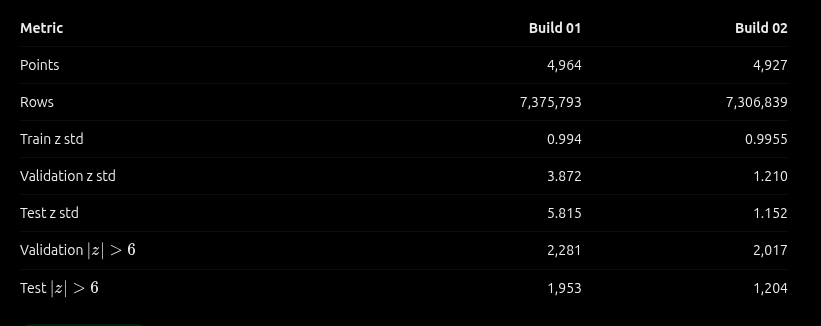

In [29]:
print(df.columns.tolist())

['key', 'state', 'region', 'year', 'month', 'split', 'target_mm', 'target_mean', 'target_sd', 'target_anom_mm', 'target_z', 'lat', 'lon', 'month_sin', 'month_cos', 'region_central', 'region_east_northeast', 'region_northwest', 'region_south_peninsula', 'rain_z_t', 'rain_z_lag1', 'rain_z_roll3', 'rain_z_roll6', 'nino34_t', 'nino34_lag1', 'nino34_lag2', 'nino34_lag3', 'nino34_mean3', 'nino34_chg3', 'dmi_t', 'dmi_lag1', 'dmi_lag2', 'dmi_lag3', 'dmi_mean3']


In [30]:
columns = [
    "split", "key", "state", "region",
    "year", "month",
    "target_mm", "target_mean", "target_sd", "target_z"
]

top_extremes = (
    df.assign(abs_z=df["target_z"].abs())
      .nlargest(20, "abs_z")[columns + ["abs_z"]]
      .reset_index(drop=True)
)

display(top_extremes)

,split,key,state,region,year,month,target_mm,target_mean,target_sd,target_z,abs_z
0,val,15757350,Maharashtra,central,2005,12,377.488556,1.662288,5.010414,75.009026,75.009026
1,val,16007350,Maharashtra,central,2005,12,314.687866,2.076215,5.729725,54.559624,54.559624
2,val,16007375,Maharashtra,central,2005,12,206.885880,2.025415,5.000000,40.972092,40.972092
3,val,26008425,Bihar,east_northeast,2007,10,955.177307,24.191626,25.402960,36.648708,36.648708
4,test,11257675,Tamilnadu,south_peninsula,2025,4,2371.270996,160.254776,67.612900,32.701099,32.701099
5,test,21258125,Chhattishgarh,central,2016,2,1393.643066,42.348801,42.940655,31.468878,31.468878
6,val,19007400,Maharashtra,central,2005,6,5489.159180,378.473663,163.626358,31.233877,31.233877
7,val,19007425,Maharashtra,central,2005,5,3834.748291,276.458832,115.632111,30.772503,30.772503
8,test,11257675,Tamilnadu,south_peninsula,2024,4,2185.876221,160.254776,67.612900,29.959097,29.959097
9,test,11257675,Tamilnadu,south_peninsula,2024,5,2107.608398,125.427948,66.342537,29.877970,29.877970


In [32]:
print(monthly.columns.tolist())

['key', 'year', 'month', 'rain_mm', 'days_present', 'days_expected']


In [35]:

results = []

for _, row in top_extremes.head(3).iterrows():
    origin = pd.Period(
        year=int(row["year"]),
        month=int(row["month"]),
        freq="M"
    )

    target_months = [origin + i for i in (1, 2, 3)]

    target_years = [p.year for p in target_months]
    target_month_numbers = [p.month for p in target_months]

    values = monthly[
        (monthly["key"].astype(str) == str(row["key"])) &
        (
            (
                (monthly["year"] == target_years[0]) &
                (monthly["month"] == target_month_numbers[0])
            ) |
            (
                (monthly["year"] == target_years[1]) &
                (monthly["month"] == target_month_numbers[1])
            ) |
            (
                (monthly["year"] == target_years[2]) &
                (monthly["month"] == target_month_numbers[2])
            )
        )
    ].sort_values(["year", "month"])

    expected_months = [(p.year, p.month) for p in target_months]
    actual_months = list(zip(values["year"], values["month"]))

    monthly_values = values["rain_mm"].tolist()

    reconstructed_total = (
        sum(monthly_values) if len(monthly_values) == 3 else np.nan
    )

    results.append({
        "key": row["key"],
        "state": row["state"],
        "origin_year": row["year"],
        "origin_month": row["month"],
        "target_months": expected_months,
        "monthly_rainfall_mm": monthly_values,
        "months_found": actual_months,
        "target_mm": row["target_mm"],
        "reconstructed_total": reconstructed_total,
        "difference": reconstructed_total - row["target_mm"]
            if len(monthly_values) == 3 else np.nan,
        "all_months_found": actual_months == expected_months
    })

display(pd.DataFrame(results))


,key,state,origin_year,origin_month,target_months,monthly_rainfall_mm,months_found,target_mm,reconstructed_total,difference,all_months_found
0,15757350,Maharashtra,2005,12,"[(2006, 1), (2006, 2), (2006, 3)]","[0.0, 0.0, 377.4885559082031]","[(2006, 1), (2006, 2), (2006, 3)]",377.488556,377.488556,0.0,True
1,16007350,Maharashtra,2005,12,"[(2006, 1), (2006, 2), (2006, 3)]","[0.0, 0.0, 314.6878662109375]","[(2006, 1), (2006, 2), (2006, 3)]",314.687866,314.687866,0.0,True
2,16007375,Maharashtra,2005,12,"[(2006, 1), (2006, 2), (2006, 3)]","[0.0, 0.0, 206.88587951660156]","[(2006, 1), (2006, 2), (2006, 3)]",206.885880,206.885880,0.0,True
